# ML from Scratch - 09 - PCA

## Importing

In [1]:
import importlib
import my_pca

importlib.reload(my_pca)
from my_pca import PCA

## Synthetic Data

In [2]:
import numpy as np

np.random.seed(42)

n_samples = 1000

Z = np.random.randn(n_samples, 3)

X = np.column_stack([
    3 * Z[:, 0] + 0.2 * Z[:, 1],
    2 * Z[:, 0] + Z[:, 1],
    4 * Z[:, 1] + 0.1 * Z[:, 2],
    2 * Z[:, 2],
    np.random.randn(n_samples) * 0.1
])

X

array([[ 1.4624896 ,  0.855164  , -0.48828835,  1.29537708, -0.19078076],
       [ 4.52225889,  2.81190634, -0.96002719, -0.46827391, -0.0860385 ],
       [ 4.89112539,  3.92586036,  3.02279148, -0.93894877, -0.04136055],
       ...,
       [ 1.82076233,  1.2762735 ,  0.26692655, -0.42441794, -0.03202978],
       [-2.84025928, -1.8263564 ,  0.33569733,  0.51550508,  0.16433782],
       [-3.65844644, -2.14934473,  1.32117976, -0.3105181 ,  0.03606479]],
      shape=(1000, 5))

In [3]:
pca = PCA()

pca.fit(X)

In [4]:
pca.cumulative_explained_variance

array([0.53720798, 0.88442936, 0.99968328, 1.        , 1.        ])

In [5]:
pca = PCA(n_components=3)

X_reduced = pca.fit_transform(X)

X_reduced

array([[-0.24991361,  1.70280151, -1.35096194],
       [-1.20323224,  5.28695067,  0.31342569],
       [-5.27092575,  4.55145778,  0.92506544],
       ...,
       [-1.119152  ,  1.94765522,  0.38660025],
       [ 1.0123358 , -3.25149115, -0.4279461 ],
       [ 0.4563844 , -4.40792199,  0.45563999]], shape=(1000, 3))

## House Prices

### Data Loading

In [6]:
import pandas as pd

X_full_preprocessed = pd.read_csv('../data/house_prices/preprocessed/full.csv').set_index('Id')
X_test_preprocessed = pd.read_csv('../data/house_prices/preprocessed/test.csv').set_index('Id')
y = pd.read_csv('../data/house_prices/preprocessed/y_full.csv').set_index('Id').squeeze('columns')

X_full_preprocessed.head()

,num__MSSubClass,num__LotArea,num__OverallQual,num__OverallCond,num__YearBuilt,num__YearRemodAdd,num__BsmtFinSF1,num__BsmtUnfSF,num__TotalBsmtSF,num__GrLivArea,...,obj__PavedDrive_P,obj__PavedDrive_Y,obj__SaleType_New,obj__SaleType_WD,obj__SaleType_infrequent_sklearn,obj__SaleCondition_Alloca,obj__SaleCondition_Family,obj__SaleCondition_Normal,obj__SaleCondition_Partial,obj__SaleCondition_infrequent_sklearn
Id,,,,,,,,,,,,,,,,,,,,,
1,0.073375,-0.400528,0.651479,-0.517200,1.050994,0.878668,0.758521,-1.065792,-0.628577,0.571005,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-0.872563,0.003940,-0.071836,2.179628,0.156734,-0.429577,1.468518,-0.705255,0.665118,-0.546879,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.073375,0.584263,0.651479,-0.517200,0.984752,0.830215,0.184258,-0.301669,-0.424645,0.760646,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.309859,-0.013645,0.651479,-0.517200,-1.863632,-0.720298,-0.520520,-0.016469,-0.947221,0.588472,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.073375,1.642914,1.374795,-0.517200,0.951632,0.733308,0.625396,-0.150997,0.292305,1.689638,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [7]:
pca = PCA()

pca.fit(X_full_preprocessed)

In [8]:
cev = pca.cumulative_explained_variance

(cev[cev <= 0.98]), len(cev[cev <= 0.98]), len(cev)

(array([0.20409635, 0.28089968, 0.35585554, 0.41324251, 0.45984893,
        0.50042713, 0.5341398 , 0.56662851, 0.59636205, 0.62520421,
        0.64684242, 0.66752437, 0.68599447, 0.70205961, 0.71580795,
        0.72858725, 0.73963304, 0.75018933, 0.76040716, 0.77012626,
        0.77972424, 0.78843076, 0.7965904 , 0.80429964, 0.8117217 ,
        0.81894922, 0.82590517, 0.83242229, 0.83872821, 0.84448426,
        0.85012951, 0.8555237 , 0.86086287, 0.86603903, 0.87100018,
        0.87562255, 0.88007093, 0.88416573, 0.88806627, 0.89185803,
        0.89540508, 0.89890194, 0.90223938, 0.90544912, 0.90851578,
        0.9114103 , 0.91413883, 0.91682811, 0.91949071, 0.92194507,
        0.92426834, 0.92657674, 0.92873946, 0.93085642, 0.93296981,
        0.93499541, 0.93697836, 0.938894  , 0.94066415, 0.94242795,
        0.94411778, 0.94575644, 0.94734012, 0.9489075 , 0.95041953,
        0.95187193, 0.95328848, 0.95462451, 0.95591627, 0.957194  ,
        0.95842797, 0.95965074, 0.96084005, 0.96

In [9]:
from sklearn.decomposition import PCA as PCA_sklearn

pca_sklearn = PCA_sklearn()

pca_sklearn.fit(X_full_preprocessed)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [10]:
cev_sklearn = np.cumsum(pca_sklearn.explained_variance_ratio_)

(cev_sklearn[cev_sklearn <= 0.98]), len(cev_sklearn[cev_sklearn <= 0.98]), len(cev_sklearn)

(array([0.20409635, 0.28089968, 0.35585554, 0.41324251, 0.45984893,
        0.50042713, 0.5341398 , 0.56662851, 0.59636205, 0.62520421,
        0.64684242, 0.66752437, 0.68599447, 0.70205961, 0.71580795,
        0.72858725, 0.73963304, 0.75018933, 0.76040716, 0.77012626,
        0.77972424, 0.78843076, 0.7965904 , 0.80429964, 0.8117217 ,
        0.81894922, 0.82590517, 0.83242229, 0.83872821, 0.84448426,
        0.85012951, 0.8555237 , 0.86086287, 0.86603903, 0.87100018,
        0.87562255, 0.88007093, 0.88416573, 0.88806627, 0.89185803,
        0.89540508, 0.89890194, 0.90223938, 0.90544912, 0.90851578,
        0.9114103 , 0.91413883, 0.91682811, 0.91949071, 0.92194507,
        0.92426834, 0.92657674, 0.92873946, 0.93085642, 0.93296981,
        0.93499541, 0.93697836, 0.938894  , 0.94066415, 0.94242795,
        0.94411778, 0.94575644, 0.94734012, 0.9489075 , 0.95041953,
        0.95187193, 0.95328848, 0.95462451, 0.95591627, 0.957194  ,
        0.95842797, 0.95965074, 0.96084005, 0.96

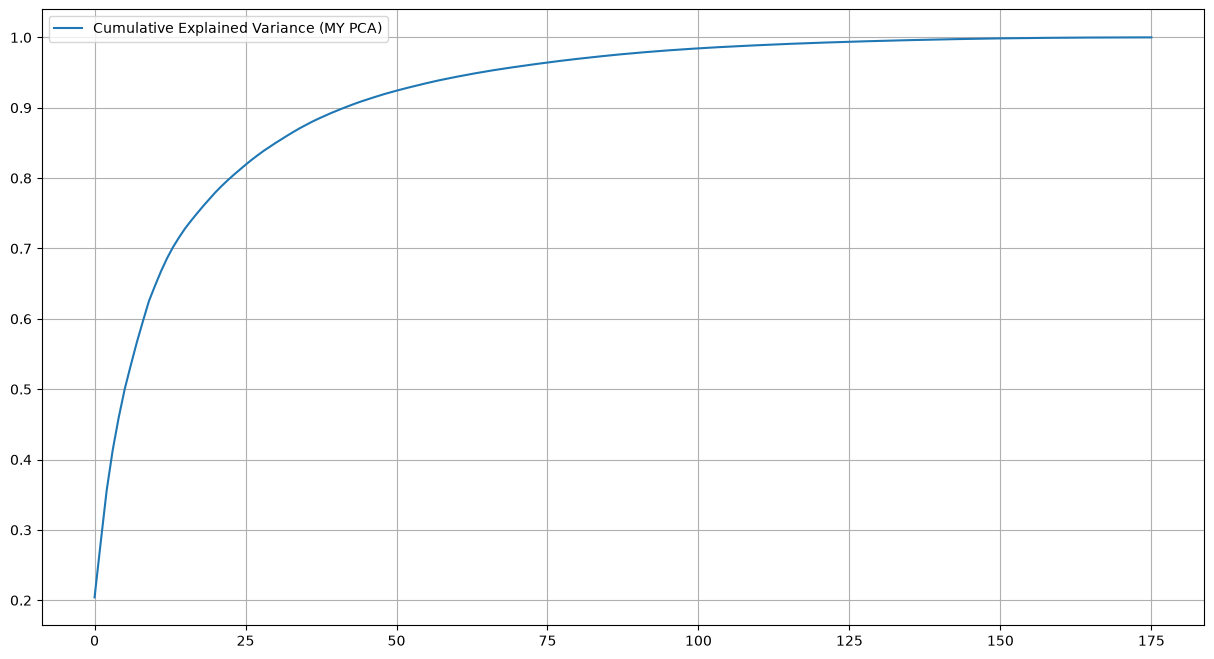

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))

plt.plot(cev, label='Cumulative Explained Variance (MY PCA)')

plt.grid()
plt.legend()
plt.show()

### Linear regression Training

In [12]:
pca = PCA(n_components=93)

X_reduced = pca.fit_transform(X_full_preprocessed)

X_reduced.head()

,0,1,2,3,4,5,6,7,8,9,...,83,84,85,86,87,88,89,90,91,92
Id,,,,,,,,,,,,,,,,,,,,,
1,1.785651,1.000631,1.754054,-1.176633,-0.006882,1.521543,0.556996,1.912325,-1.018647,-0.015258,...,-0.023356,0.017264,-0.192339,0.043718,-0.132860,0.461696,0.034117,-0.058496,0.050434,-0.038549
2,-0.043070,1.584149,-1.490278,-0.321744,-0.710871,0.284602,-0.397305,0.643918,0.487634,-1.340085,...,0.364468,-0.145856,-0.179678,0.357694,-0.018363,0.307204,0.186510,-0.144749,-0.157650,-0.205277
3,2.582105,0.325480,0.669375,-0.757631,-0.304584,-0.111051,0.555645,1.358384,1.011949,0.996438,...,0.064554,0.020235,-0.114919,-0.031335,-0.122539,0.483899,0.091978,-0.063488,0.049751,-0.063473
4,-0.690877,-0.938859,-0.401950,-0.169554,-0.537557,-0.083992,1.799335,-0.085143,-0.442197,-1.624845,...,0.137034,-0.201734,-0.293081,-0.178021,-0.374812,0.276241,0.045993,0.206150,-0.013432,-0.074465
5,4.124686,-0.429194,-0.769994,-0.874162,-0.285658,-0.741033,-0.087859,1.618827,1.020237,1.490870,...,-0.026890,-0.159055,-0.696942,0.521205,-0.234142,0.062461,-0.102950,-0.191488,-0.037448,-0.097353


In [13]:
import sys
sys.path.append('../01 - Linear Regression')

from my_linear_regression import Linear_Regression

model = Linear_Regression()

model.fit(X_reduced, y)

In [14]:
X_test_reduced = pca.transform(X_test_preprocessed)

y_test = model.predict(X_test_reduced)
y_test

Id
1461    109320.085600
1462    162667.050099
1463    188500.601044
1464    192161.122116
1465    175126.570006
            ...      
2915     92478.427373
2916     90735.593858
2917    173030.896039
2918    116021.609701
2919    220168.276246
Length: 1459, dtype: float64

In [15]:
submission_df = pd.DataFrame(y_test, columns=['SalePrice'], index=y_test.index)

submission_df.to_csv('../data/house_prices/submissions/submission_linear_regression_after_pca.csv', sep=',')

Kaggle Score before PCA: `0.16664` (RMSE)

Kaggle Score After PCA: `0.15865` (RMSE) (lower, better and faster)

## Titanic

In [16]:
X_full_preprocessed = pd.read_csv('../data/titanic/preprocessed/full.csv').set_index('PassengerId')
X_test_preprocessed = pd.read_csv('../data/titanic/preprocessed/test.csv').set_index('PassengerId')
y = pd.read_csv('../data/titanic/preprocessed/y_full.csv').set_index('PassengerId').squeeze('columns')

X_full_preprocessed.head()

,num__Age,num__Fare,num__FamilySize,num__SibSp,num__Parch,obj__Embarked_C,obj__Embarked_Q,obj__Embarked_S,gender__Sex,pass__Pclass,pass__IsAlone
PassengerId,,,,,,,,,,,
1,-0.565736,-0.502445,0.059160,0.432793,-0.473674,0.0,0.0,1.0,1.0,3.0,0.0
2,0.663861,0.786845,0.059160,0.432793,-0.473674,1.0,0.0,0.0,0.0,1.0,0.0
3,-0.258337,-0.488854,-0.560975,-0.474545,-0.473674,0.0,0.0,1.0,0.0,3.0,1.0
4,0.433312,0.420730,0.059160,0.432793,-0.473674,0.0,0.0,1.0,0.0,1.0,0.0
5,0.433312,-0.486337,-0.560975,-0.474545,-0.473674,0.0,0.0,1.0,1.0,3.0,1.0


In [17]:
pca = PCA()

pca.fit(X_full_preprocessed)

In [18]:
cev = pca.cumulative_explained_variance

(cev[cev <= 0.98]), len(cev[cev <= 0.98]), len(cev)

(array([0.40994905, 0.63744618, 0.75584838, 0.84514785, 0.89462259,
        0.93966235, 0.97007615]),
 7,
 11)

In [19]:
pca_sklearn = PCA_sklearn()

pca_sklearn.fit(X_full_preprocessed)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [20]:
cev_sklearn = np.cumsum(pca_sklearn.explained_variance_ratio_)

(cev_sklearn[cev_sklearn <= 0.98]), len(cev_sklearn[cev_sklearn <= 0.98]), len(cev_sklearn)

(array([0.40994905, 0.63744618, 0.75584838, 0.84514785, 0.89462259,
        0.93966235, 0.97007615]),
 7,
 11)

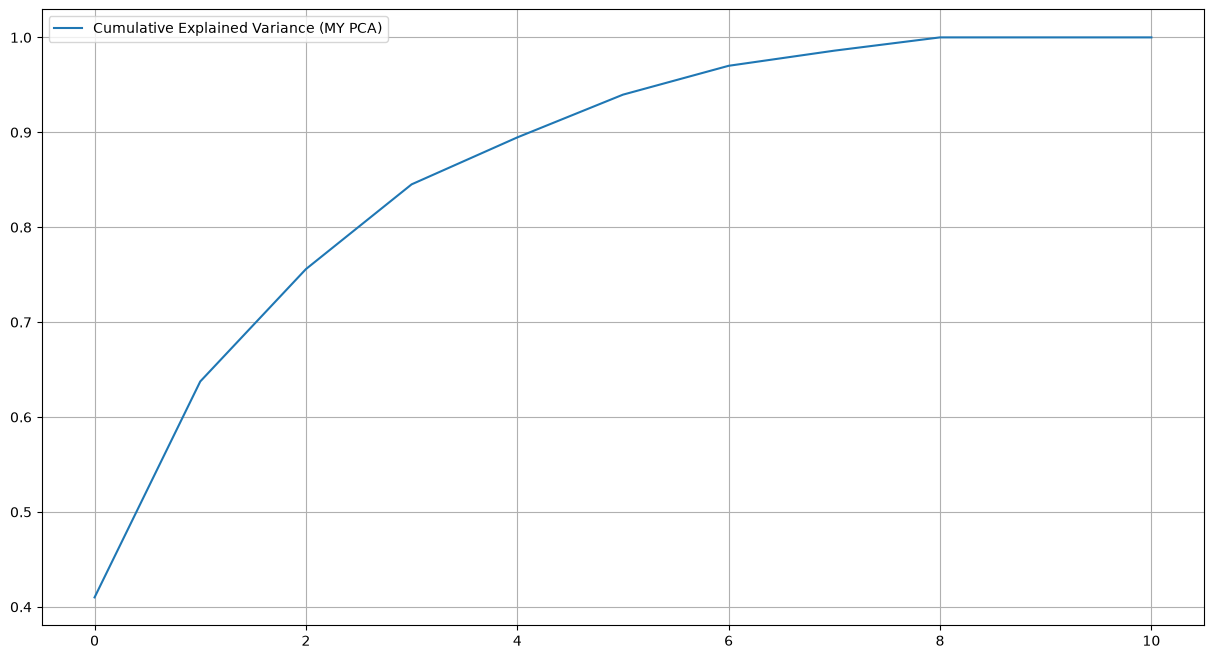

In [21]:
plt.figure(figsize=(15, 8))

plt.plot(cev, label='Cumulative Explained Variance (MY PCA)')

plt.grid()
plt.legend()
plt.show()

In [22]:
pca = PCA(n_components=8)

X_reduced = pca.fit_transform(X_full_preprocessed)

X_reduced.head()

,0,1,2,3,4,5,6,7
PassengerId,,,,,,,,
1,-0.041349,2.473015,0.297122,0.513646,1.367118,-1.592034,0.244756,0.841518
2,-0.052545,-0.302001,0.219215,0.639464,1.413680,-0.147964,-0.067543,0.534482
3,1.006811,2.234717,0.202443,-0.191629,1.514456,-1.543080,-0.582975,0.146825
4,-0.047378,0.204637,0.415227,0.605568,0.522604,-1.066006,-0.464846,0.425091
5,1.225743,1.966162,0.842416,-0.073827,1.686102,-1.863341,0.275149,0.267424


In [23]:
import sys
sys.path.append('../02 - Logistic Regression')

from my_logistic_regression import Logistic_Regression

model = Logistic_Regression()

model.fit(X_reduced, y)

In [24]:
X_test_reduced = pca.transform(X_test_preprocessed)

y_test = model.predict(X_test_reduced)
y_test

array([0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1,
       1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0,

In [25]:
submission_df = pd.DataFrame(y_test, columns=['Survived'], index=X_test_reduced.index)

submission_df.to_csv('../data/titanic/submissions/submission_logistic_regression_after_pca.csv', sep=',')

Kaggle Score before PCA: `0.76315` (accuracy)

Kaggle Score After PCA: `0.76315` (accuracy) (same, but faster)